# 11 · FHN synaptic pairs: excitatory and inhibitory source types
## Goal
Establish a synaptic input contract and test isolated E/I interactions before a network. Keep the FHN intrinsic dynamics from earlier notebooks and add one smooth release gate per source. Test gates, driving-force signs, one-way transmission and reciprocal pairs.

This is a dimensionless phenomenological construction, not calibrated AMPA/GABA physiology. E/I labels specify **outgoing synaptic type**, not a different FHN equation or a guaranteed change in firing rate. Figures, events, scan tables and parameters are saved under `results/fhn_synaptic_pair/`. NumPy, SciPy, pandas, Matplotlib and Jupyter are required; no internet or previous notebook state is required.

## Observed results
The notebook completes **6 one-way and 24 reciprocal pair experiments**, with **16 passed checks** and **5 figures**.

- With recipient I=0.2, baseline and I-source cases have no positive v=0 crossings in time 400–1000; the E-source case has 15. These are finite-window event counts, not a proof of an asymptotically stable resting state.
- At recipient I=0.5, all three one-way cases have 15 crossings in that window, despite different waveforms and timing. E/I input sign does not determine event-count changes by itself.
- The selected reciprocal EI case (g=0.08, offset 0.2) has period-based frequency about **0.0280903943** per model-time unit in both neurons, versus **0.0253328644** for the uncoupled oscillator. Its phase-locking value is near 1 with lag **0.0944320 cycles**, while full-state RMS difference is **1.52060**: phase locking is not complete synchronization.
- The selected II case at the same g and offset is approximately antiphase (wrapped lag −0.5 cycles). The EE state difference remains small but nonzero in the finite window; no complete attractor classification is inferred from these cuts.

For the selected EI benchmark, independent DOP853/Radau solutions agree within **4.13e-08** in state coordinates and **2.08e-08** in spike time. The later 1400–2000 window retains period frequency about 0.0280903943 and lag about 0.0944320 cycles. Count frequencies differ by endpoint inclusion, and RMS state difference varies slightly because equal-duration windows need not span an integer number of cycles.

Across sampled trajectories v ranges from **-1.995411 to 1.943056**, inside the declared reversals −3 and +3. Together with nonnegative conductances and gates, this supports the stated input signs in these runs. These coordinates and rates remain dimensionless.


## Setup: interaction and sign conventions
$$\dot v_i=v_i-v_i^3/3-w_i+I_i+I_i^{syn},\qquad
\dot w_i=\epsilon(v_i+a-bw_i),$$
$$\dot s_j=\alpha q(v_j)(1-s_j)-\beta s_j,\qquad
q(v)=\frac1{1+\exp[-(v-v_{rel})/k]},$$
$$I_i^{syn}=\sum_jG_{ij}s_j(E_j-v_i),\qquad G_{ij}\ge0,\quad G_{ii}=0.$$
Rows are recipients and columns sources. Positive input increases activation v. Each source's reversal E applies to all its outgoing edges. Thus a later network can assign an E/I label per node and keep all outgoing contacts consistent, without negative conductances. Gates can be shared among outgoing edges only because their kinetics here depend on the source, not on the recipient or edge.

Use a=0.7, b=0.8, ε=0.08; $E_E=3,E_I=-3$, $v_{rel}=0,k=0.1,\alpha=1,\beta=0.2$. These are **declared exploratory parameters in FHN coordinates**, not voltages, milliseconds or fitted receptor constants. Both source types use the same kinetics to isolate the reversal effect. Closing time when q=0 is 1/β=5; at q≈1, gate relaxation time is 1/(α+β)≈0.8333 and plateau α/(α+β)=5/6. Smooth q is nonzero at every finite v, including below release threshold: this is graded release, not a spike-triggered jump process. Positive v=0 events measure spikes but do not trigger gates.

At s=0 the derivative is αq≥0; at s=1 it is −β<0, so [0,1] is invariant analytically. With v clamped, $s_\infty=\alpha q/(\alpha q+\beta)$ and
$$s(t)=s_\infty+(s(0)-s_\infty)e^{-(\alpha q+\beta)t}.$$
Reversal driving force changes sign when recipient v crosses E. We explicitly check whether the demonstrated trajectories stay between the chosen reversals. Synaptic activation adds the instantaneous slope $-\sum_jG_{ij}s_j$ to v dynamics at fixed gates, explaining a shunting contribution. It does not imply that the full coupled Jacobian has only negative synaptic effects.

Background: [Neuronal Dynamics §3.1](https://neuronaldynamics.epfl.ch/online/Ch3.S1.html) describes conductance/reversal currents and first-order binding gates. Its displayed current uses the outward-positive convention; the inward-positive input here uses E−v. Our sigmoid release and numerical constants are explicitly chosen variants, not a reproduction of that text's physiological examples.

In [1]:
from pathlib import Path
import json, platform
import numpy as np
import pandas as pd
import scipy, matplotlib
from scipy.integrate import solve_ivp
from scipy.optimize import brentq
from scipy.special import expit
from IPython.display import display
import matplotlib.pyplot as plt
OUT=Path('results/fhn_synaptic_pair');OUT.mkdir(parents=True,exist_ok=True)
a,b,eps=.7,.8,.08
ALPHA,BETA,VREL,WIDTH=1.,.2,0.,.1
REVERSAL={'E':3.,'I':-3.}
END,BURN=1000.,400.;STEP=.2
BLUE,ORANGE,GRAY='#2166AC','#C56A18','#555555'
plt.rcParams.update({'font.size':11,'figure.dpi':110,'savefig.dpi':160,'axes.spines.top':False,
 'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})
versions=dict(python=platform.python_version(),numpy=np.__version__,scipy=scipy.__version__,pandas=pd.__version__,matplotlib=matplotlib.__version__)
print(versions)
def save(fig,name):
 fig.savefig(OUT/(name+'.png'),bbox_inches='tight');plt.show();plt.close(fig)
def release(v):return expit((np.asarray(v)-VREL)/WIDTH)
def rest(current):
 v=brentq(lambda v:v**3/3+(1/b-1)*v+a/b-current,-5,5)
 return np.array([v,(v+a)/b,0.])
def synaptic_input(v,s,G,E):return G@(s*E)-v*(G@s)
def integrate(initial,currents,types,G,end=END,method='DOP853',rtol=1e-9,atol=1e-11):
 initial=np.asarray(initial,float);currents=np.asarray(currents,float);G=np.asarray(G,float)
 n=len(currents);E=np.array([REVERSAL[t] for t in types])
 if initial.shape!=(n,3) or G.shape!=(n,n) or E.shape!=(n,):raise ValueError('Shape mismatch')
 if not np.isfinite(initial).all() or not np.isfinite(G).all() or np.any(G<0) or np.any(np.diag(G)!=0):raise ValueError('Invalid conductance or initial state')
 if np.any(initial[:,2]<0) or np.any(initial[:,2]>1):raise ValueError('Initial gates outside [0,1]')
 def rhs(t,y):
  v,w,s=y.reshape(n,3).T
  return np.column_stack((v-v**3/3-w+currents+synaptic_input(v,s,G,E),eps*(v+a-b*w),
   ALPHA*release(v)*(1-s)-BETA*s)).ravel()
 events=[]
 for i in range(n):
  def event(t,y,index=i):return y[3*index]
  event.direction=1;event.terminal=False;events.append(event)
 sol=solve_ivp(rhs,(0,end),initial.ravel(),method=method,rtol=rtol,atol=atol,
  dense_output=True,events=events,max_step=.25)
 if not sol.success:raise RuntimeError(sol.message)
 return sol
checks=[]
def check(name,error,limit):checks.append(dict(check=name,error=float(error),limit=limit,passed=bool(error<limit)))

{'python': '3.12.2', 'numpy': '2.2.6', 'scipy': '1.18.1', 'pandas': '3.0.6', 'matplotlib': '3.11.2'}


## 1. Validate clamped release and reversal currents
Clamped-gate tests compare integration with the exact exponential. The current plot holds the gate at s=0.5 and G=0.1 to show the sign dependence on recipient activation; it is a diagnostic calculation, not another neuron simulation.

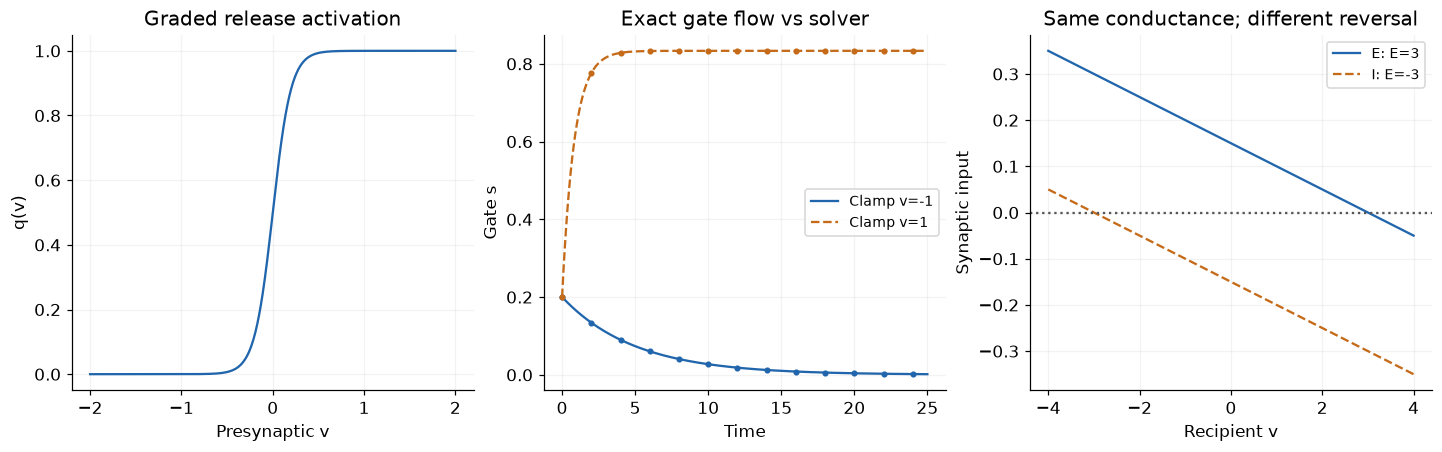

Isolated FHN period: 39.47441498023568


In [3]:
fig,axs=plt.subplots(1,3,figsize=(13,4),layout='constrained')
vgrid=np.linspace(-2,2,801);axs[0].plot(vgrid,release(vgrid),color=BLUE)
axs[0].set(xlabel='Presynaptic v',ylabel='q(v)',title='Graded release activation')
tt=np.linspace(0,25,501)
for vc,color,style in [(-1.,BLUE,'-'),(1.,ORANGE,'--')]:
 q=float(release(vc));rate=ALPHA*q+BETA;steady=ALPHA*q/rate
 exact=steady+(.2-steady)*np.exp(-rate*tt)
 sol=solve_ivp(lambda t,s:ALPHA*q*(1-s)-BETA*s,(0,25),[.2],dense_output=True,rtol=1e-11,atol=1e-13)
 check(f'Clamped gate v={vc:g}',np.max(abs(sol.sol(tt)[0]-exact)),1e-9)
 axs[1].plot(tt,exact,color=color,linestyle=style,label=f'Clamp v={vc:g}')
 axs[1].plot(tt[::40],sol.sol(tt[::40])[0],'o',color=color,markersize=3)
axs[1].set(xlabel='Time',ylabel='Gate s',title='Exact gate flow vs solver');axs[1].legend(fontsize=9)
post=np.linspace(-4,4,801)
for typ,color,style in [('E',BLUE,'-'),('I',ORANGE,'--')]:axs[2].plot(post,.1*.5*(REVERSAL[typ]-post),color=color,linestyle=style,label=f'{typ}: E={REVERSAL[typ]:g}')
axs[2].axhline(0,color=GRAY,linestyle=':');axs[2].set(xlabel='Recipient v',ylabel='Synaptic input',title='Same conductance; different reversal');axs[2].legend(fontsize=9)
save(fig,'01_gate_and_driving_force')
# Initialize all gates at zero, to avoid unexplained pre-existing transmitter activity.
iso=integrate([[2.,-.5,0.]],[.5],['E'],np.zeros((1,1)),end=800.)
t0,t1=iso.t_events[0][-2:];PERIOD=t1-t0
cycle=lambda fraction:np.r_[iso.sol(t0+fraction*PERIOD)[:2],0.]
print('Isolated FHN period:',PERIOD)
INITIAL={q:np.array([cycle(0),cycle(q)]) for q in [.2,.5]}
pd.DataFrame([dict(offset=q,node=i,v=z[0],w=z[1],s=z[2]) for q,zs in INITIAL.items() for i,z in enumerate(zs)]).to_csv(OUT/'initial_states.csv',index=False)

## 2. One-way transmission: test E and I before recurrence
Neuron 1 is an autonomous oscillator (I₁=0.5). Only $G_{21}$ is nonzero, so its activation/recovery trajectory must be independent of the recipient and source type. At I₂=0.2 the recipient starts at its isolated resting equilibrium; at I₂=0.5 it starts on the isolated cycle. For each current, the initial state is identical across baseline, E and I conditions. Baseline G=0 and source E/I at G₂₁=0.08 give six experiments.

Measure window 400–1000. Inhibitory input can alter timing, suppress firing or yield rebound effects; an instantaneous negative input is not proof that every long-time firing-rate comparison decreases. No adaptive search for preferred outcomes is used.

,target_current,source_type,g,node,window_spikes,count_frequency,period_frequency,isi_cv
1,0.2,baseline,0.00,1,0,0.000,NaN,NaN
3,0.2,E,0.08,1,15,0.025,0.025333,1.191048e-12
5,0.2,I,0.08,1,0,0.000,NaN,NaN
7,0.5,baseline,0.00,1,15,0.025,0.025333,1.018943e-14
9,0.5,E,0.08,1,15,0.025,0.025333,4.774646e-08
11,0.5,I,0.08,1,15,0.025,0.025333,2.750809e-05


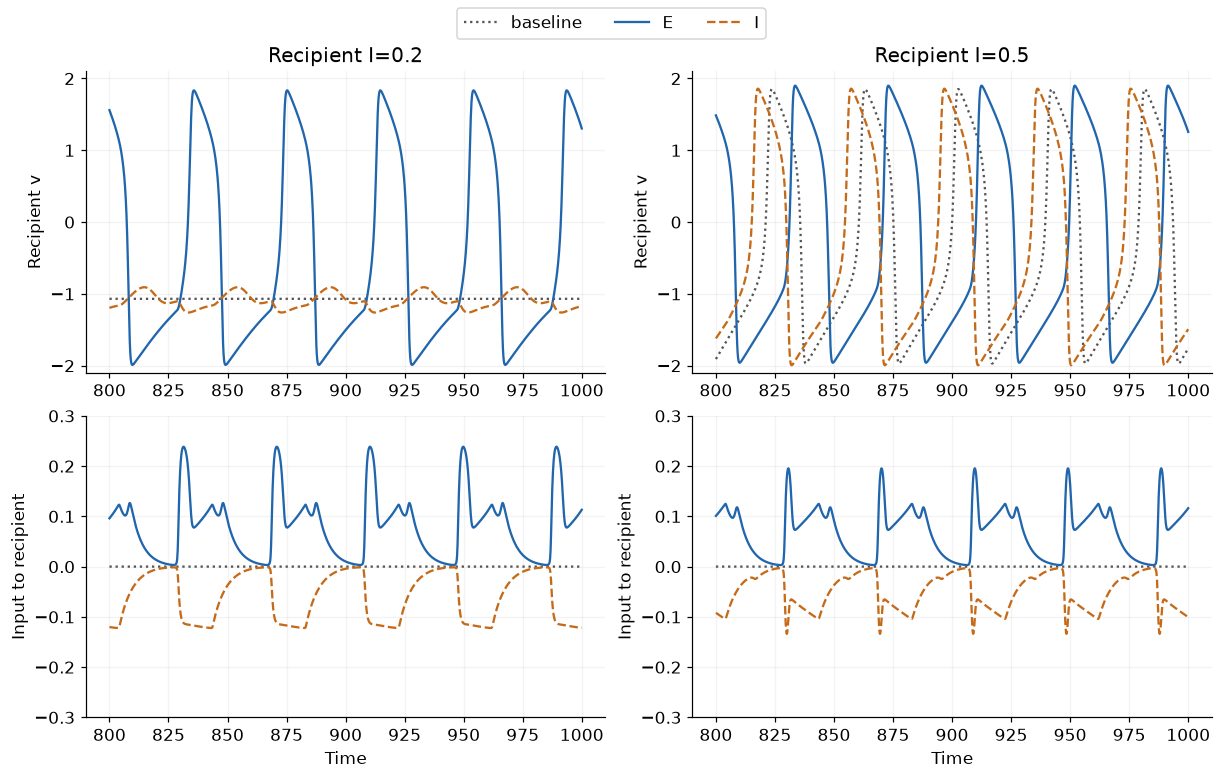

In [5]:
def node_stats(sol,start=BURN,stop=END):
 records=[]
 for i,e in enumerate(sol.t_events):
  recent=e[(e>=start)&(e<=stop)];isi=np.diff(recent)
  records.append(dict(node=i,window_spikes=len(recent),count_frequency=len(recent)/(stop-start),
   period_frequency=float(1/isi.mean()) if len(isi)>=2 else np.nan,
   isi_cv=float(isi.std()/isi.mean()) if len(isi)>=2 else np.nan))
 return records
ONE={};one_rows=[]
for target_current in [.2,.5]:
 target=rest(target_current) if target_current==.2 else cycle(.2)
 for typ,g in [('baseline',0.),('E',.08),('I',.08)]:
  types=[typ if typ!='baseline' else 'E','E'];G=np.array([[0.,0.],[g,0.]])
  sol=integrate([cycle(0),target],[.5,target_current],types,G)
  ONE[(target_current,typ)]=sol
  for row in node_stats(sol):one_rows.append(dict(target_current=target_current,source_type=typ,g=g,**row))
one_table=pd.DataFrame(one_rows);one_table.to_csv(OUT/'one_way_metrics.csv',index=False)
display(one_table[one_table.node==1])
fig,axs=plt.subplots(2,2,figsize=(11,7),layout='constrained')
view=np.linspace(END-200,END,2001)
for col,current in enumerate([.2,.5]):
 for typ,color,style in [('baseline',GRAY,':'),('E',BLUE,'-'),('I',ORANGE,'--')]:
  z=ONE[(current,typ)].sol(view).reshape(2,3,-1)
  axs[0,col].plot(view,z[1,0],color=color,linestyle=style,label=typ)
  g=0 if typ=='baseline' else .08;E=REVERSAL.get(typ,3.)
  incoming=g*z[0,2]*(E-z[1,0])
  axs[1,col].plot(view,incoming,color=color,linestyle=style)
 axs[0,col].set(title=f'Recipient I={current:g}',ylabel='Recipient v',ylim=(-2.1,2.1))
 axs[1,col].set(xlabel='Time',ylabel='Input to recipient',ylim=(-.3,.3))
handles,labels=axs[0,0].get_legend_handles_labels()
fig.legend(handles,labels,loc='outside upper center',ncol=3)
save(fig,'02_one_way_transmission')

## 3. Reciprocal EE, EI and II pairs
Both intrinsic drives are 0.5. Compare source-type assignments EE, EI and II, with $G_{12}=G_{21}=g$ at g=0,0.02,0.08,0.2 and two initial cycle offsets 0.2/0.5: 24 recurrent experiments. In EI, neuron 1 has E outgoing synapses and neuron 2 has I outgoing synapses; the E neuron therefore **receives inhibition**, while the I neuron receives excitation. Source type is indexed by columns, never by recipient row.

Positive v=0 crossings have no reset and do not directly drive synaptic release. Period frequency and ISI variability use at least three retained events; absent estimates stay missing. Event phase is interpolated only between actual crossings. Pair phase-locking value uses jointly supported times and is undefined without adequate support. State RMS includes only v,w (not gates); high phase locking does not imply identical states. Count frequency is retained even when spiking ceases, but a low event count is not a stability proof for rest.

,pattern,g,count_frequency_1,count_frequency_2,state_rms_difference,phase_locking_value,lag_cycles
0,EE,0.00,0.025000,0.025000,1.868991,1.000000,-2.000000e-01
2,EE,0.08,0.023333,0.023333,0.003377,0.999999,-1.506826e-04
3,EE,0.20,0.021667,0.021667,0.000006,1.000000,-1.872427e-07
8,EI,0.00,0.025000,0.025000,1.868991,1.000000,-2.000000e-01
10,EI,0.08,0.026667,0.026667,1.520597,1.000000,9.443203e-02
11,EI,0.20,0.033333,0.033333,1.910657,1.000000,9.091004e-02
16,II,0.00,0.025000,0.025000,1.868991,1.000000,-2.000000e-01
18,II,0.08,0.023333,0.023333,2.674990,1.000000,-5.000000e-01
19,II,0.20,0.023333,0.021667,2.705871,1.000000,5.000000e-01


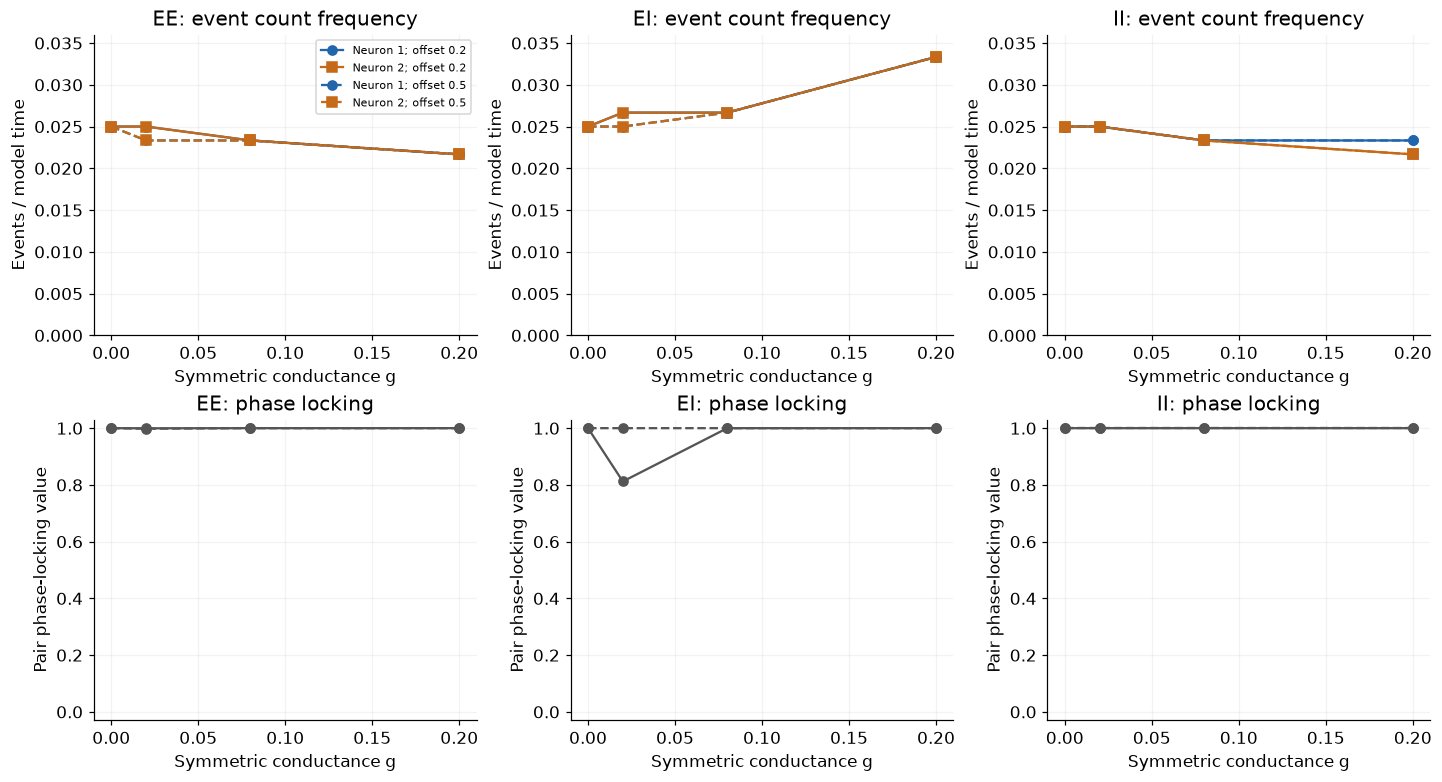

In [7]:
def pair_stats(sol):
 times=np.arange(BURN,END+STEP/10,STEP);z=sol.sol(times).reshape(2,3,-1)
 delta=z[0,:2]-z[1,:2];result={'state_rms_difference':float(np.sqrt(np.mean(np.sum(delta**2,axis=0))))}
 phases=[]
 for i,e in enumerate(sol.t_events):
  phase=np.full(len(times),np.nan)
  if len(e)>=2:
   valid=(times>=e[0])&(times<=e[-1]);phase[valid]=np.interp(times[valid],e,2*np.pi*np.arange(len(e)))
  phases.append(phase)
  for key,val in node_stats(sol)[i].items():
   if key!='node':result[f'{key}_{i+1}']=val
 d=phases[0]-phases[1];valid=np.isfinite(d);result['phase_valid_fraction']=float(valid.mean())
 if valid.sum()>10:
  order=np.mean(np.exp(1j*d[valid]));result.update(phase_locking_value=float(abs(order)),lag_cycles=float(np.angle(order)/(2*np.pi)))
 else:result.update(phase_locking_value=np.nan,lag_cycles=np.nan)
 return result
REC={};rec_rows=[]
for pattern in ['EE','EI','II']:
 for offset in [.2,.5]:
  for g in [0.,.02,.08,.2]:
   sol=integrate(INITIAL[offset],[.5,.5],list(pattern),np.array([[0.,g],[g,0.]]))
   REC[(pattern,offset,g)]=sol;rec_rows.append(dict(pattern=pattern,initial_offset=offset,g=g,**pair_stats(sol)))
rec=pd.DataFrame(rec_rows);rec.to_csv(OUT/'reciprocal_scan.csv',index=False)
display(rec[(rec.initial_offset==.2)&rec.g.isin([0.,.08,.2])][
 ['pattern','g','count_frequency_1','count_frequency_2','state_rms_difference','phase_locking_value','lag_cycles']])
fig,axs=plt.subplots(2,3,figsize=(13,7),layout='constrained')
for col,pattern in enumerate(['EE','EI','II']):
 for offset,style in [(.2,'-'),(.5,'--')]:
  part=rec[(rec.pattern==pattern)&(rec.initial_offset==offset)]
  axs[0,col].plot(part.g,part.count_frequency_1,'o'+style,color=BLUE,label=f'Neuron 1; offset {offset}')
  axs[0,col].plot(part.g,part.count_frequency_2,'s'+style,color=ORANGE,label=f'Neuron 2; offset {offset}')
  axs[1,col].plot(part.g,part.phase_locking_value,'o'+style,color=GRAY)
 axs[0,col].set(title=f'{pattern}: event count frequency',xlabel='Symmetric conductance g',ylabel='Events / model time',ylim=(0,.036))
 axs[1,col].set(title=f'{pattern}: phase locking',xlabel='Symmetric conductance g',ylabel='Pair phase-locking value',ylim=(-.03,1.03))
axs[0,0].legend(fontsize=7.5)
save(fig,'03_reciprocal_scan')

## 4. Inspect EI feedback, gates and currents
The selected EI pair at g=0.08, offset 0.2, is shown alongside a raster. Its two input channels have opposite reversal driving forces, but their sizes vary with both presynaptic gates and recipient activation. This prevents interpreting the E/I labels as constant signed forcing.

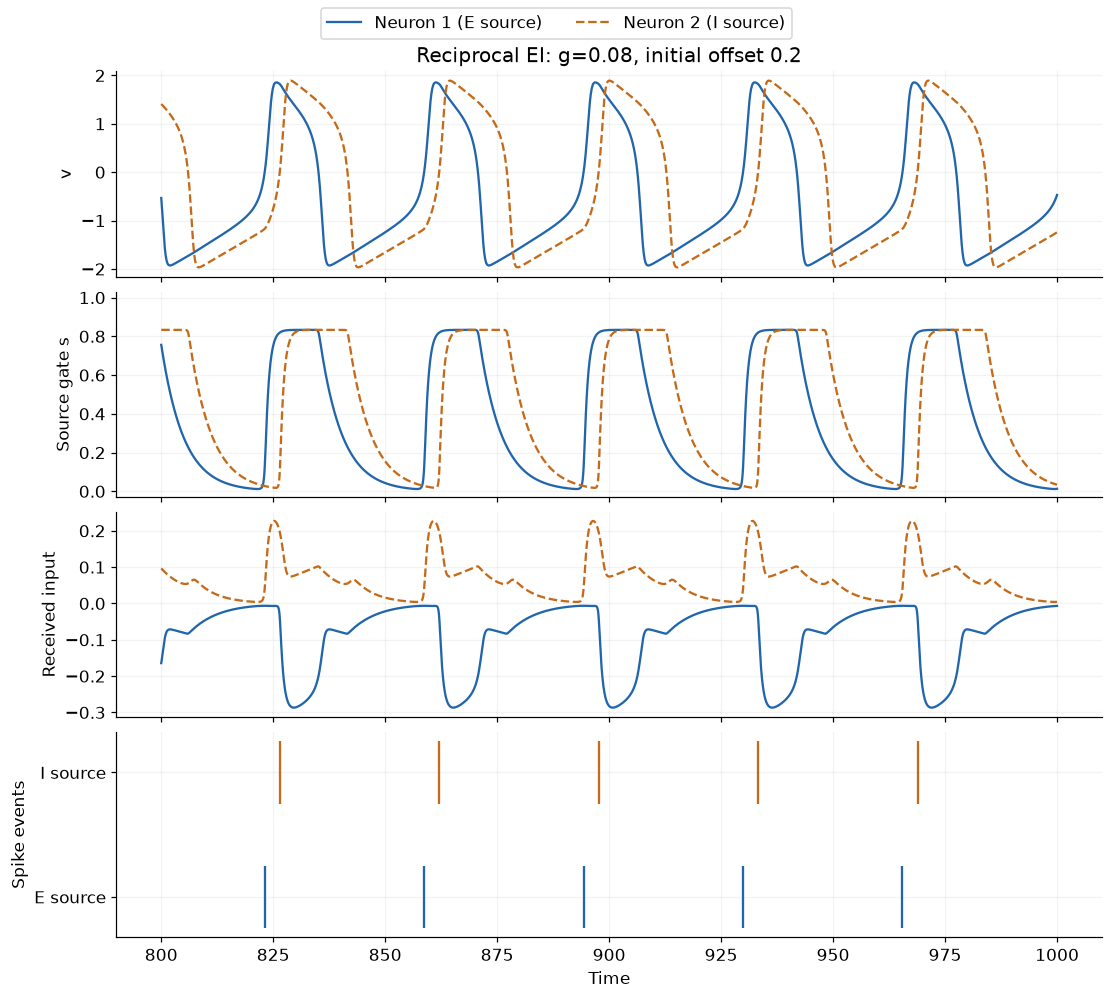

In [9]:
selected=REC[('EI',.2,.08)];times=np.linspace(END-200,END,2001);z=selected.sol(times).reshape(2,3,-1)
G=np.array([[0.,.08],[.08,0.]]);E=np.array([3.,-3.]);incoming=synaptic_input(z[:,0],z[:,2],G,E[:,None])
fig,axs=plt.subplots(4,1,figsize=(10,9),sharex=True,layout='constrained')
for i,color,style,label in [(0,BLUE,'-','Neuron 1 (E source)'),(1,ORANGE,'--','Neuron 2 (I source)')]:
 axs[0].plot(times,z[i,0],color=color,linestyle=style,label=label)
 axs[1].plot(times,z[i,2],color=color,linestyle=style)
 axs[2].plot(times,incoming[i],color=color,linestyle=style)
 e=selected.t_events[i];e=e[(e>=times[0])&(e<=times[-1])]
 axs[3].vlines(e,i-.25,i+.25,color=color)
axs[0].set(ylabel='v',title='Reciprocal EI: g=0.08, initial offset 0.2')
handles,labels=axs[0].get_legend_handles_labels()
fig.legend(handles,labels,loc='outside upper center',ncol=2)
axs[1].set(ylabel='Source gate s',ylim=(-.03,1.03));axs[2].set(ylabel='Received input')
axs[3].set(xlabel='Time',ylabel='Spike events',yticks=[0,1],yticklabels=['E source','I source'])
save(fig,'04_ei_feedback')

## 5. Structural and numerical checks
Check the source-column convention by hand, exact gate flow, analytic sign examples, gate bounds and observed reversal brackets, zero-conductance invariance, one-way source independence, and convergence against a different solver. Full autonomous trajectories, not externally replayed spike trains, are compared. A longer EI run compares two late windows; it does not certify all parameters or initial conditions.

,check,error,limit,passed
0,Clamped gate v=-1,4.461431e-13,1.000000e-09,True
1,Clamped gate v=1,1.672551e-12,1.000000e-09,True
2,Presynaptic reversal-column convention,2.775558e-17,1.000000e-12,True
3,Reversal gives zero input,0.000000e+00,1.000000e-12,True
4,Positive E input within reversal bracket,0.000000e+00,5.000000e-01,True
5,Negative I input within reversal bracket,0.000000e+00,5.000000e-01,True
6,"Sampled gates in [0,1]",0.000000e+00,1.000000e-08,True
7,Observed v above I reversal,0.000000e+00,1.000000e-08,True
8,Observed v below E reversal,0.000000e+00,1.000000e-08,True
9,"One-way source independent: I2=0.2, E",5.007044e-09,2.000000e-05,True


,window,state_rms_difference,window_spikes_1,count_frequency_1,period_frequency_1,isi_cv_1,window_spikes_2,count_frequency_2,period_frequency_2,isi_cv_2,phase_valid_fraction,phase_locking_value,lag_cycles
0,400–1000,1.520597,16,0.026667,0.02809,2.947500e-10,16,0.026667,0.02809,4.768489e-09,0.942353,1.0,0.094432
1,1400–2000,1.525484,17,0.028333,0.02809,1.060785e-12,16,0.026667,0.02809,5.192951e-12,0.942686,1.0,0.094432


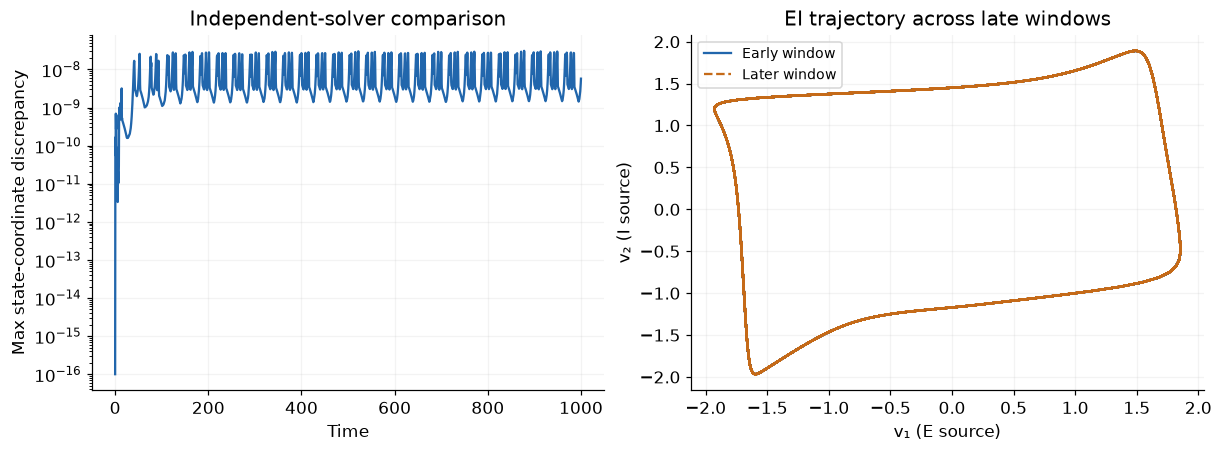

Completed 30 pair experiments and 16 passed checks.


In [11]:
# Distinguish source labels from recipient labels in an asymmetric hand calculation.
v=np.array([-.5,1.]);s=np.array([.2,.7]);G=np.array([[0.,.1],[.3,0.]]);E=np.array([3.,-3.])
expected=np.array([.1*.7*(-3.-v[0]),.3*.2*(3.-v[1])])
check('Presynaptic reversal-column convention',np.max(abs(synaptic_input(v,s,G,E)-expected)),1e-12)
check('Reversal gives zero input',abs(.1*.5*(3.-3.)),1e-12)
check('Positive E input within reversal bracket',0 if .1*.5*(3.-0.)>0 else 1,.5)
check('Negative I input within reversal bracket',0 if .1*.5*(-3.-0.)<0 else 1,.5)
# Sampled bounds complement, rather than replace, the analytical invariant-gate argument.
all_runs=list(ONE.values())+list(REC.values());bound_error=0.;low=np.inf;high=-np.inf
for sol in all_runs:
 sample=sol.sol(np.linspace(0,END,4001)).reshape(2,3,-1)
 bound_error=max(bound_error,float(max(0.,-sample[:,2].min(),sample[:,2].max()-1)))
 low=min(low,float(sample[:,0].min()));high=max(high,float(sample[:,0].max()))
check('Sampled gates in [0,1]',bound_error,1e-8)
check('Observed v above I reversal',max(0.,-3.-low),1e-8)
check('Observed v below E reversal',max(0.,high-3.),1e-8)
control_times=np.linspace(0,END,2001)
for current in [.2,.5]:
 for typ in ['E','I']:
  base=ONE[(current,'baseline')].sol(control_times)[:2]
  test=ONE[(current,typ)].sol(control_times)[:2]
  check(f'One-way source independent: I2={current:g}, {typ}',np.max(abs(test-base)),2e-5)
# At zero G, reversal assignments must not affect any state, even though gates evolve.
check('Zero coupling independent of reversal types',np.max(abs(REC[('EE',.2,0.)].sol(control_times)-REC[('EI',.2,0.)].sol(control_times))),1e-12)
G=np.array([[0.,.08],[.08,0.]])
ref=integrate(INITIAL[.2],[.5,.5],['E','I'],G,method='Radau',rtol=2e-10,atol=2e-12)
state_error=float(np.max(abs(selected.sol(control_times)-ref.sol(control_times))))
check('DOP853 versus Radau state convergence',state_error,2e-4)
event_error=0.
for e,er in zip(selected.t_events,ref.t_events):
 assert len(e)==len(er)
 event_error=max(event_error,float(np.max(abs(e-er)))) if len(e) else event_error
check('DOP853 versus Radau spike times',event_error,2e-4)
validation=pd.DataFrame(checks);validation.to_csv(OUT/'validation_checks.csv',index=False);display(validation)
assert validation.passed.all()
long=integrate(INITIAL[.2],[.5,.5],['E','I'],G,end=2000.)
# Shifted output supports the existing fixed-window metric without extrapolation.
class Shifted:
 t_events=[e-1000 for e in long.t_events]
 def sol(self,t):return long.sol(np.asarray(t)+1000)
windows=pd.DataFrame([dict(window='400–1000',**pair_stats(selected)),dict(window='1400–2000',**pair_stats(Shifted()))])
windows.to_csv(OUT/'window_sensitivity.csv',index=False);display(windows)
fig,axs=plt.subplots(1,2,figsize=(11,4),layout='constrained')
axs[0].semilogy(control_times,np.maximum(np.max(abs(selected.sol(control_times)-ref.sol(control_times)),axis=0),1e-16),color=BLUE)
axs[0].set(xlabel='Time',ylabel='Max state-coordinate discrepancy',title='Independent-solver comparison')
for label,run,color,style in [('Early window',selected,BLUE,'-'),('Later window',Shifted(),ORANGE,'--')]:
 samples=run.sol(np.arange(BURN,END+STEP/10,STEP)).reshape(2,3,-1)
 axs[1].plot(samples[0,0],samples[1,0],color=color,linestyle=style,label=label)
axs[1].set(xlabel='v₁ (E source)',ylabel='v₂ (I source)',title='EI trajectory across late windows');axs[1].legend(fontsize=9)
save(fig,'05_numerical_and_window_checks')
event_rows=[]
for (pattern,offset,g),sol in REC.items():
 for i,events in enumerate(sol.t_events):
  event_rows.extend(dict(pattern=pattern,offset=offset,g=g,node=i,time=float(t)) for t in events)
pd.DataFrame(event_rows).to_csv(OUT/'reciprocal_spike_events.csv',index=False)
one_events=[]
for (current,typ),sol in ONE.items():
 for i,events in enumerate(sol.t_events):
  one_events.extend(dict(target_current=current,source_type=typ,node=i,time=float(t)) for t in events)
pd.DataFrame(one_events).to_csv(OUT/'one_way_spike_events.csv',index=False)
summary=dict(versions=versions,units='dimensionless',parameters=dict(a=a,b=b,epsilon=eps,alpha=ALPHA,beta=BETA,release_threshold=VREL,release_width=WIDTH,reversals=REVERSAL),
 duration=END,burn_in=BURN,step=STEP,one_way_experiments=len(ONE),reciprocal_experiments=len(REC),
 checks_passed=int(validation.passed.sum()),state_convergence_error=state_error,event_convergence_error=event_error,
 sampled_v_range=[low,high],isolated_period=float(PERIOD))
(OUT/'summary.json').write_text(json.dumps(summary,indent=2))
print('Completed',len(ONE)+len(REC),'pair experiments and',len(checks),'passed checks.')

## Next step: an E/I lattice with the validated synaptic rule
Reuse the nearest-neighbor or distance kernel $K_{ij}\ge0$ as the spatial factor, specify conductance as $G_{ij}=g_jK_{ij}$ (or an explicitly normalized variant), and assign E/I source types by columns. Keep the intrinsic model, input map, release rule and gate kinetics fixed initially. E/I fractions, spatial assignments, E/I strength ratios and initial-condition seeds become separately controlled parameters. No particular fraction or balanced state is assumed here. First compare all-E/all-I controls with a mixed assignment on one fixed graph before graph-family comparisons or heterogeneous intrinsic models.

### Provenance and limitations
[Neuronal Dynamics §3.1](https://neuronaldynamics.epfl.ch/online/Ch3.S1.html) supports the reversal-current and first-order gate framework; our sign, graded release and dimensionless parameters are stated explicitly. [SciPy solve_ivp](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html) documents numerical integration and event handling. Sources consulted during preparation on 2026-10-27. No biological synapse constants are imported into uncalibrated FHN coordinates.

No axonal delay, spike-triggered gate jump, receptor subtype model, plasticity, stochastic release, noise, adaptation beyond FHN recovery, or physical calibration is included. Equal α/β is a comparison control, not a physiological E/I claim. Finite event counts and short grids in g do not locate bifurcations or establish asymptotic silence, balance, chaos or all basins. The analytic gate invariant holds for the continuous equations; reported voltage ranges and numerical bounds are sampled checks. Logarithmic numerical-discrepancy plots use a display floor of 10⁻¹⁶.